In [52]:
%pip install seaborn
%pip install plotly


import pandas as pd
import matplotlib.pyplot as plt
import sys 
#sys.path.append('/Users/luisfuentes/Library/Python/3.9/lib/python/site-packages')
import plotly.express as px

df_1 = pd.read_csv("https://raw.githubusercontent.com/lasyaharini-cloud/Diabetes-Prediction/main/data/diabetes_012_health_indicators_BRFSS2021.csv")

/Users/luisfuentes/miniconda3/envs/ml_env/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
/Users/luisfuentes/miniconda3/envs/ml_env/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [53]:
df_1 = df_1.copy()
df_1 = df_1.drop_duplicates()
keep = [
    'CholCheck', 'HighBP', 'HighChol', 'GenHlth', 
    'HeartDiseaseorAttack', 'Sex', 'Stroke', 'Diabetes_012'
]
data = df_1[keep].copy()
X = data.iloc[:, :-1]
y = data['Diabetes_012'].copy()


In [55]:
import xgboost as xgb
from sklearn.metrics import log_loss, classification_report, average_precision_score
from sklearn.metrics import roc_curve, roc_auc_score
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split, RandomizedSearchCV
from sklearn import preprocessing
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, recall_score

from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y,
     test_size=0.20, random_state=42, stratify=y)

#standarization of the data
std_scale = preprocessing.StandardScaler()
X_train = std_scale.fit_transform(X_train)
X_test = std_scale.transform(X_test)



base = xgb.XGBClassifier( #RandomForestClassifierxgb.XGBClassifier
	objective="multi:softmax",
	eval_metric="logloss",
	random_state=42,
)

bb = BalancedBaggingClassifier(
	estimator=base,
	sampling_strategy='auto',
	replacement=False,
	random_state=42
)

param_dist = {
    # hyperparameters
    "estimator__learning_rate"    : [0.01, 0.05, 0.1, 0.2],
    "estimator__max_depth"        : [3, 4, 5, 6, 7, 10],
    "estimator__n_estimators"     : [100, 200, 300],      
    "estimator__subsample"        : [0.6, 0.7, 0.8, 0.9],
    "estimator__colsample_bytree" : [0.6, 0.7, 0.8, 0.9],
    "estimator__min_child_weight" : [1, 3, 5],
    "estimator__reg_alpha"        : [0, 0.01, 0.1],       # L1
    "estimator__reg_lambda"       : [1, 1.5, 2.0],        # L2
    # BB Classifier hyperparameters 
    "n_estimators"                : [10, 20, 30, 50],         
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
	estimator          = bb,
	param_distributions= param_dist,
    n_iter             = 30,          # number of random combinations to try
    scoring            = "f1_macro",  # macro F1 handles class imbalance well
    cv                 = cv_strategy,
    n_jobs             = -1,          # use all CPU cores
    random_state       = 42,
    verbose            = 2,
    refit              = True,        # refit best model on full X_train
)


print("Running RandomizedSearchCV …")
search.fit(X_train, y_train)

print("\n===== Cross-Validation Results =====")
print(f"Best CV F1-macro : {search.best_score_:.4f}")
print(f"Best parameters  : {search.best_params_}")



Running RandomizedSearchCV …
Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END estimator__colsample_bytree=0.9, estimator__learning_rate=0.2, estimator__max_depth=7, estimator__min_child_weight=1, estimator__n_estimators=100, estimator__reg_alpha=0.1, estimator__reg_lambda=2.0, estimator__subsample=0.7, n_estimators=30; total time=  34.5s
[CV] END estimator__colsample_bytree=0.9, estimator__learning_rate=0.2, estimator__max_depth=7, estimator__min_child_weight=1, estimator__n_estimators=100, estimator__reg_alpha=0.1, estimator__reg_lambda=2.0, estimator__subsample=0.7, n_estimators=30; total time=  35.1s
[CV] END estimator__colsample_bytree=0.9, estimator__learning_rate=0.2, estimator__max_depth=7, estimator__min_child_weight=1, estimator__n_estimators=100, estimator__reg_alpha=0.1, estimator__reg_lambda=2.0, estimator__subsample=0.7, n_estimators=30; total time=  35.1s
[CV] END estimator__colsample_bytree=0.9, estimator__learning_rate=0.2, estimator__max_depth=7, 


Top 5 CV candidates:
    rank_test_score  mean_test_score  std_test_score  \
10                1         0.417734        0.001124   
25                2         0.417097        0.001059   
18                3         0.416590        0.002921   
21                4         0.416342        0.001472   
22                5         0.416222        0.002461   

                                               params  
10  {'n_estimators': 30, 'estimator__subsample': 0...  
25  {'n_estimators': 50, 'estimator__subsample': 0...  
18  {'n_estimators': 10, 'estimator__subsample': 0...  
21  {'n_estimators': 50, 'estimator__subsample': 0...  
22  {'n_estimators': 20, 'estimator__subsample': 0...  

Fitting final model with best hyperparameters …

 Multi-class classification results 
              precision    recall  f1-score   support

     Class 0     0.9274    0.6306    0.7507     36908
     Class 1     0.0343    0.1879    0.0580      1123
     Class 2     0.3154    0.6354    0.4215      6679



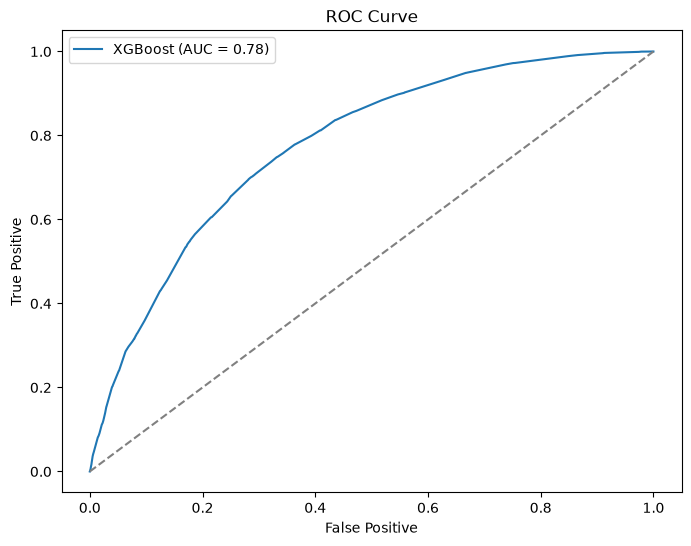

Confusion Matrix:
[[23275  4923  8710]
 [  409   211   503]
 [ 1413  1022  4244]]
Recall             : 0.4846
Specificity (Cl 2) : 0.7578
Precision   (Cl 2) : 0.3154
F1 Score           : 0.4101
Accuracy           : 0.6202


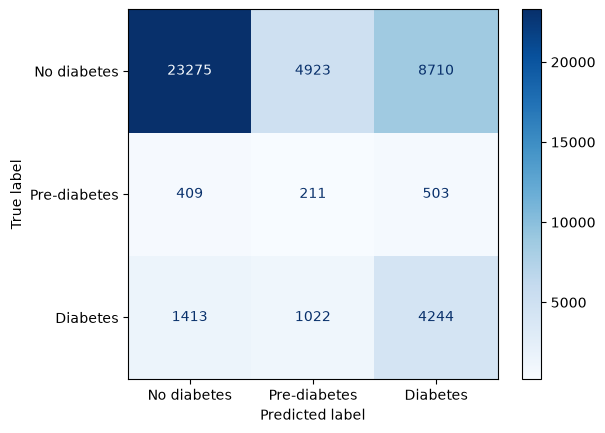

In [56]:
import pandas as pd
cv_results = (
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")
    [["rank_test_score", "mean_test_score", "std_test_score", "params"]]
)
print("\nTop 5 CV candidates:")
print(cv_results.head())

#REFIT BEST MODEL WITH FULL ESTIMATORS

best_params = search.best_params_.copy()

final_xgb = xgb.XGBClassifier(
    objective            = "multi:softprob",
    eval_metric          = "mlogloss",
    num_class            = 3,
    random_state         = 42,
    verbosity            = 0,
    # XGBoost params from CV (strip the "estimator__" prefix)
    learning_rate        = best_params.get("estimator__learning_rate",    0.1),
    max_depth            = best_params.get("estimator__max_depth",         5),
    n_estimators         = 500,          # full count for final model
    subsample            = best_params.get("estimator__subsample",        0.8),
    colsample_bytree     = best_params.get("estimator__colsample_bytree", 0.8),
    min_child_weight     = best_params.get("estimator__min_child_weight",   1),
    reg_alpha            = best_params.get("estimator__reg_alpha",         0),
    reg_lambda           = best_params.get("estimator__reg_lambda",        1),
)

bb = BalancedBaggingClassifier(
    estimator        = final_xgb,
    n_estimators     = 50,           # full BBC bags for final model
    sampling_strategy= "auto",
    replacement      = False,
    random_state     = 42,
)

print("\nFitting final model with best hyperparameters …")
bb.fit(X_train, y_train)


# EVALUATE THE FINAL MODEL ON THE TEST SET

probs = bb.predict_proba(X_test)
preds = bb.predict(X_test)

print("\n Multi-class classification results ")
print(classification_report(
    y_test, preds,
    target_names=["Class 0", "Class 1", "Class 2"],
    digits=4
))

print("Log loss:", log_loss(y_test, probs, labels=[0.0, 1.0, 2.0]))

class_2_index   = list(bb.classes_).index(2.0)
y_test_class_2  = (y_test == 2.0).astype(int)

print("Class 2 PR-AUC:",
      average_precision_score(y_test_class_2, probs[:, class_2_index]))

fpr, tpr, thresholds = roc_curve(y_test_class_2, probs[:, class_2_index])
auc_score = roc_auc_score(y_test_class_2, probs[:, class_2_index])

multiclass_auc = roc_auc_score(
    y_test, probs,
    multi_class="ovr", average="macro", labels=bb.classes_
)
print(f"Macro ROC-AUC: {multiclass_auc:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"XGBoost (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive")
plt.ylabel("True Positive")
plt.title("ROC Curve")
plt.legend()
plt.show()

confusion = confusion_matrix(y_test, preds, labels=[0.0, 1.0, 2.0])
tn  = confusion[:2, :2].sum()
fp  = confusion[:2, 2].sum()
fn  = confusion[2, :2].sum()
tp  = confusion[2, 2]

recall      = recall_score(y_test, preds, labels=[0.0,1.0,2.0], average="macro")
f1          = f1_score(y_test, preds, labels=[0.0,1.0,2.0], average="macro")
precision   = tp / (fp + tp)
specificity = tn / (tn + fp)
accuracy    = (preds == y_test).mean()

print("Confusion Matrix:")
print(confusion)
print(f"Recall             : {recall:.4f}")
print(f"Specificity (Cl 2) : {specificity:.4f}")
print(f"Precision   (Cl 2) : {precision:.4f}")
print(f"F1 Score           : {f1:.4f}")
print(f"Accuracy           : {accuracy:.4f}")

disp = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=["No diabetes", "Pre-diabetes", "Diabetes"]
)
disp.plot(cmap=plt.cm.Blues)
plt.show()

### Binary analysis -- Diabetes or not

In [ ]:
import xgboost as xgb
from sklearn.metrics import log_loss, classification_report, average_precision_score, precision_recall_curve
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.model_selection import StratifiedKFold, train_test_split, RandomizedSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, recall_score

df_1 = df_1.copy()
df_1 = df_1.drop_duplicates()
keep = [
    'CholCheck', 'HighBP', 'HighChol', 'GenHlth', 
    'HeartDiseaseorAttack', 'Sex', 'Stroke', 'Diabetes_012'
]
data = df_1[keep].copy()
data = data[data["Diabetes_012"].isin([0, 2])]
data["Diabetes_012"] = data["Diabetes_012"].replace({2: 1})
prediabites = data[data["Diabetes_012"] == 1]
y = data["Diabetes_012"]
X = data.iloc[:,1:]


X_train, X_test, y_train, y_test = train_test_split(X, y,
     test_size=0.20, random_state=42, stratify=y)

#standarization of the data
std_scale = preprocessing.StandardScaler()
X_train = std_scale.fit_transform(X_train)
X_test = std_scale.transform(X_test)

base = xgb.XGBClassifier(
	objective="binary:logistic",
	eval_metric="logloss",
	random_state=42,
)

bb = BalancedBaggingClassifier(
	estimator=base,
	sampling_strategy='auto',
	replacement=False,
	random_state=42
)

param_dist = {
    # hyperparameters
    "estimator__learning_rate"    : [0.01, 0.05, 0.1, 0.2],
    "estimator__max_depth"        : [3, 4, 5, 6, 7, 10],
    "estimator__n_estimators"     : [100, 200, 300],      
    "estimator__subsample"        : [0.6, 0.7, 0.8, 0.9],
    "estimator__colsample_bytree" : [0.6, 0.7, 0.8, 0.9],
    "estimator__min_child_weight" : [1, 3, 5],
    "estimator__reg_alpha"        : [0, 0.01, 0.1],       # L1
    "estimator__reg_lambda"       : [1, 1.5, 2.0],        # L2
    # BB Classifier hyperparameters 
    "n_estimators"                : [10, 20, 30, 50],         
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator          = bb,
    param_distributions= param_dist,
    n_iter             = 30,          # number of random combinations to try
    scoring            = "f1_macro",  # macro F1 handles class imbalance well
    cv                 = cv_strategy,
    n_jobs             = -1,          # use all CPU cores
    random_state       = 42,
    verbose            = 2,
    refit              = True,        # refit best model on full X_train
)

search.fit(X_train, y_train)

best_params = search.best_params_

print("\n Cross-Validation Results ")
print(f"Best CV F1-macro : {search.best_score_:.4f}")
print(f"Best parameters  : {best_params}")




Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END estimator__colsample_bytree=0.9, estimator__learning_rate=0.2, estimator__max_depth=7, estimator__min_child_weight=1, estimator__n_estimators=100, estimator__reg_alpha=0.1, estimator__reg_lambda=2.0, estimator__subsample=0.7, n_estimators=30; total time=   4.2s
[CV] END estimator__colsample_bytree=0.9, estimator__learning_rate=0.2, estimator__max_depth=7, estimator__min_child_weight=1, estimator__n_estimators=100, estimator__reg_alpha=0.1, estimator__reg_lambda=2.0, estimator__subsample=0.7, n_estimators=30; total time=   4.3s
[CV] END estimator__colsample_bytree=0.9, estimator__learning_rate=0.2, estimator__max_depth=7, estimator__min_child_weight=1, estimator__n_estimators=100, estimator__reg_alpha=0.1, estimator__reg_lambda=2.0, estimator__subsample=0.7, n_estimators=30; total time=   4.3s
[CV] END estimator__colsample_bytree=0.9, estimator__learning_rate=0.2, estimator__max_depth=7, estimator__min_child_weight=1


Top 5 CV candidates:
    rank_test_score  mean_test_score  std_test_score  \
0                 1              1.0             0.0   
27                1              1.0             0.0   
26                1              1.0             0.0   
25                1              1.0             0.0   
24                1              1.0             0.0   

                                               params  
0   {'n_estimators': 30, 'estimator__subsample': 0...  
27  {'n_estimators': 10, 'estimator__subsample': 0...  
26  {'n_estimators': 50, 'estimator__subsample': 0...  
25  {'n_estimators': 50, 'estimator__subsample': 0...  
24  {'n_estimators': 20, 'estimator__subsample': 0...  
Log loss: 5.1108551321845665e-05
Diabetes PR-AUC: 1.0


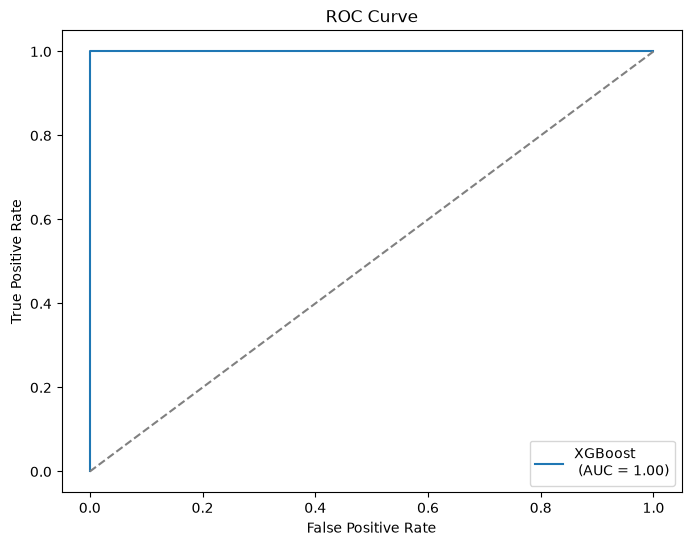

Confusion Matrix:
[[36909     0]
 [    0  6679]]
Recall: 1.0000
Specificity: 1.0000
Precision: 1.0000
F1 Score: 1.0000
Accuracy: 1.0000


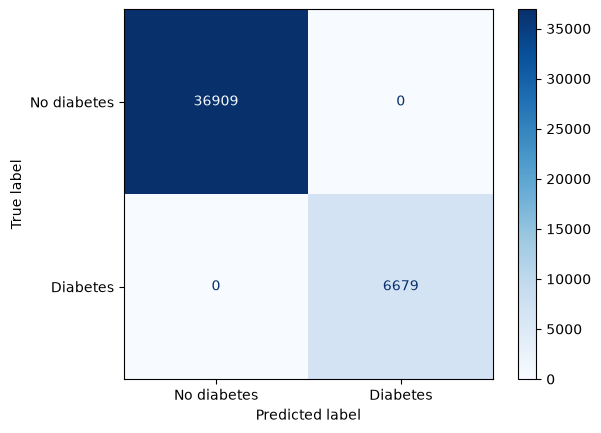

In [ ]:
cv_results = (
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")
    [["rank_test_score", "mean_test_score", "std_test_score", "params"]]
)
print("\nTop 5 CV candidates:")
print(cv_results.head())

best_params = search.best_params_.copy()

final_xgb = xgb.XGBClassifier(
    objective            = "binary:logistic",
    eval_metric          = "logloss",
    random_state         = 42,
    verbosity            = 0,
    # XGBoost params from CV (strip the "estimator__" prefix)
    learning_rate        = best_params.get("estimator__learning_rate",    0.1),
    max_depth            = best_params.get("estimator__max_depth",         5),
    n_estimators         = 500,          # full count for final model
    subsample            = best_params.get("estimator__subsample",        0.8),
    colsample_bytree     = best_params.get("estimator__colsample_bytree", 0.8),
    min_child_weight     = best_params.get("estimator__min_child_weight",   1),
    reg_alpha            = best_params.get("estimator__reg_alpha",         0),
    reg_lambda           = best_params.get("estimator__reg_lambda",        1),
)

bb = BalancedBaggingClassifier(
    estimator        = final_xgb,
    n_estimators     = 50,           # full BBC bags for final model
    sampling_strategy= "auto",
    replacement      = False,
    random_state     = 42,
)

bb.fit(
	X_train,
	y_train
)

eval_set = [(X_train, y_train), (X_test, y_test)]


probs = bb.predict_proba(X_test)[:, 1]
preds = bb.predict(X_test)

print("Log loss:", log_loss(y_test, probs))


print(
    "Diabetes PR-AUC:",
    average_precision_score(y_test, probs)
)

fpr, tpr, thresholds = roc_curve(y_test, probs)

auc_score = roc_auc_score(y_test, probs)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'XGBoost\n (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

confusion = confusion_matrix(y_test, preds)
tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()


recall = recall_score(y_test, preds)
specificity = tn/(tn + fp)
precision = tp/(fp + tp)
f1 = f1_score(y_test, preds)
accuracy = (tp + tn) / (tp + tn + fp + fn)
print('Confusion Matrix:')
print(confusion)
print(f"Recall: {recall:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Precision: {precision:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Accuracy: {accuracy:.4f}")
disp = ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=['No diabetes', 'Diabetes'])
disp.plot(cmap=plt.cm.Blues)

plt.show()

###Random Forest

In [ ]:
import xgboost as xgb
from sklearn.metrics import log_loss, classification_report, average_precision_score
from sklearn.metrics import roc_curve, roc_auc_score
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split, RandomizedSearchCV
from sklearn import preprocessing
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, recall_score

from sklearn.ensemble import RandomForestClassifier
df_1 = df_1.copy()
df_1 = df_1.drop_duplicates()
keep = [
    'CholCheck', 'HighBP', 'HighChol', 'GenHlth', 
    'HeartDiseaseorAttack', 'Sex', 'Stroke', 'Diabetes_012'
]
data = df_1[keep].copy()
X = data.iloc[:, :-1]
y = data['Diabetes_012'].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y,
     test_size=0.20, random_state=42, stratify=y)

#standarization of the data
std_scale = preprocessing.StandardScaler()
X_train = std_scale.fit_transform(X_train)
X_test = std_scale.transform(X_test)


base = RandomForestClassifier( #RandomForestClassifierxgb.XGBClassifier
	random_state=42,
)

bb = BalancedBaggingClassifier(
	estimator=base,
	sampling_strategy='auto',
	replacement=False,
	random_state=42
)

param_dist = {
    # Random Forest hyperparameters
    "estimator__n_estimators": [100, 200, 300],
    "estimator__max_depth": [None, 5, 10, 15, 20],
    "estimator__max_features": ["sqrt", "log2", None],
    "estimator__min_samples_split": [2, 5, 10],
    "estimator__min_samples_leaf": [1, 2, 4],
    "estimator__bootstrap": [True, False],
    # Balanced Bagging hyperparameters
    "n_estimators": [10, 20, 30, 50],
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
	estimator          = bb,
	param_distributions= param_dist,
    n_iter             = 30,          # number of random combinations to try
    scoring            = "f1_macro",  # macro F1 handles class imbalance well
    cv                 = cv_strategy,
    n_jobs             = -1,         
    random_state       = 42,
    verbose            = 2,
    refit              = True,        # refit best model on full X_train
)


print("Running RandomizedSearchCV …")
search.fit(X_train, y_train)

print("\n Cross-Validation Results ")
print(f"Best CV F1-macro : {search.best_score_:.4f}")
print(f"Best parameters  : {search.best_params_}")

Running RandomizedSearchCV …
Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END estimator__bootstrap=True, estimator__max_depth=10, estimator__max_features=log2, estimator__min_samples_leaf=4, estimator__min_samples_split=10, estimator__n_estimators=300, n_estimators=10; total time=  12.4s
[CV] END estimator__bootstrap=True, estimator__max_depth=10, estimator__max_features=log2, estimator__min_samples_leaf=4, estimator__min_samples_split=10, estimator__n_estimators=300, n_estimators=10; total time=  12.6s
[CV] END estimator__bootstrap=True, estimator__max_depth=10, estimator__max_features=log2, estimator__min_samples_leaf=4, estimator__min_samples_split=10, estimator__n_estimators=300, n_estimators=10; total time=  12.6s
[CV] END estimator__bootstrap=True, estimator__max_depth=10, estimator__max_features=log2, estimator__min_samples_leaf=4, estimator__min_samples_split=10, estimator__n_estimators=300, n_estimators=10; total time=  12.6s
[CV] END estimator__bootstrap


Top 5 CV candidates:
    rank_test_score  mean_test_score  std_test_score  \
12                1         0.414652        0.001126   
26                2         0.414649        0.001266   
10                3         0.414631        0.001173   
8                 4         0.414618        0.001209   
7                 5         0.412758        0.003589   

                                               params  
12  {'n_estimators': 50, 'estimator__n_estimators'...  
26  {'n_estimators': 50, 'estimator__n_estimators'...  
10  {'n_estimators': 30, 'estimator__n_estimators'...  
8   {'n_estimators': 30, 'estimator__n_estimators'...  
7   {'n_estimators': 20, 'estimator__n_estimators'...  

Fitting final model with best hyperparameters …

===== Multi-class classification results =====
              precision    recall  f1-score   support

     Class 0     0.9264    0.6317    0.7512     36908
     Class 1     0.0337    0.1852    0.0570      1123
     Class 2     0.3160    0.6323    0.4214  

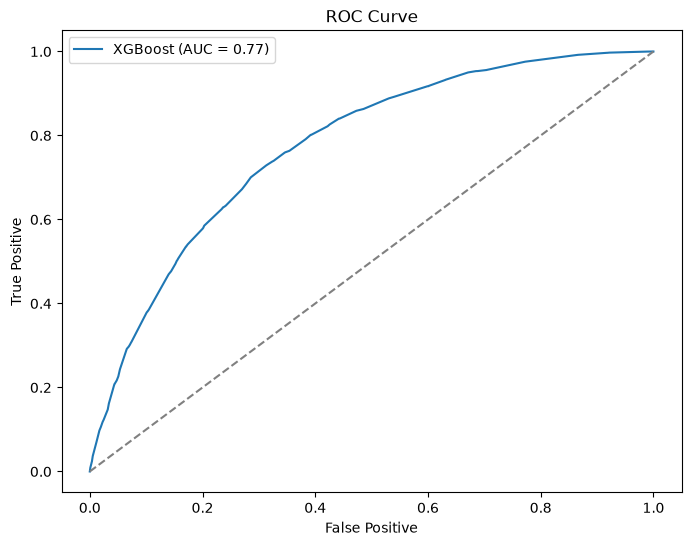

Confusion Matrix:
[[23315  4951  8642]
 [  415   208   500]
 [ 1437  1019  4223]]
Recall             : 0.4831
Specificity (Cl 2) : 0.7596
Precision   (Cl 2) : 0.3160
F1 Score           : 0.4098
Accuracy           : 0.6206


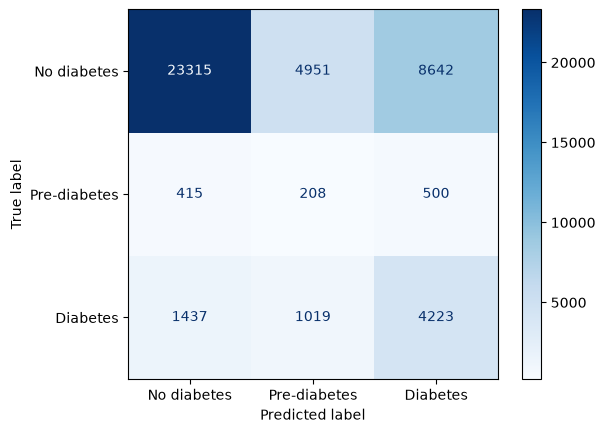

In [ ]:
import pandas as pd
cv_results = (
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")
    [["rank_test_score", "mean_test_score", "std_test_score", "params"]]
)
print("\nTop 5 CV candidates:")
print(cv_results.head())

#REFIT BEST MODEL WITH FULL ESTIMATORS

best_params = search.best_params_.copy()

final_xgb = RandomForestClassifier(
    random_state         = 42,

    max_depth            = best_params.get("estimator__max_depth",         5),
    n_estimators         = best_params.get("estimator__n_estimators",     500),
    max_features         = best_params.get("estimator__max_features",     "sqrt"),
    min_samples_split    = best_params.get("estimator__min_samples_split", 2),
    min_samples_leaf     = best_params.get("estimator__min_samples_leaf", 1),
    bootstrap            = best_params.get("estimator__bootstrap",         True),
)

bb = BalancedBaggingClassifier(
    estimator        = final_xgb,
    n_estimators     = 50,           # full BBC bags for final model
    sampling_strategy= "auto",
    replacement      = False,
    random_state     = 42,
)

print("\nFitting final model with best hyperparameters …")
bb.fit(X_train, y_train)

# EVALUATE THE FINAL MODEL ON THE TEST SET

probs = bb.predict_proba(X_test)
preds = bb.predict(X_test)

print("\n Multi-class classification results ")
print(classification_report(
    y_test, preds,
    target_names=["Class 0", "Class 1", "Class 2"],
    digits=4
))

print("Log loss:", log_loss(y_test, probs, labels=[0.0, 1.0, 2.0]))

class_2_index   = list(bb.classes_).index(2.0)
y_test_class_2  = (y_test == 2.0).astype(int)

print("Class 2 PR-AUC:",
      average_precision_score(y_test_class_2, probs[:, class_2_index]))

fpr, tpr, thresholds = roc_curve(y_test_class_2, probs[:, class_2_index])
auc_score = roc_auc_score(y_test_class_2, probs[:, class_2_index])

multiclass_auc = roc_auc_score(
    y_test, probs,
    multi_class="ovr", average="macro", labels=bb.classes_
)
print(f"Macro ROC-AUC: {multiclass_auc:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"XGBoost (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive")
plt.ylabel("True Positive")
plt.title("ROC Curve")
plt.legend()
plt.show()

confusion = confusion_matrix(y_test, preds, labels=[0.0, 1.0, 2.0])
tn  = confusion[:2, :2].sum()
fp  = confusion[:2, 2].sum()
fn  = confusion[2, :2].sum()
tp  = confusion[2, 2]

recall      = recall_score(y_test, preds, labels=[0.0,1.0,2.0], average="macro")
f1          = f1_score(y_test, preds, labels=[0.0,1.0,2.0], average="macro")
precision   = tp / (fp + tp)
specificity = tn / (tn + fp)
accuracy    = (preds == y_test).mean()

print("Confusion Matrix:")
print(confusion)
print(f"Recall             : {recall:.4f}")
print(f"Specificity (Cl 2) : {specificity:.4f}")
print(f"Precision   (Cl 2) : {precision:.4f}")
print(f"F1 Score           : {f1:.4f}")
print(f"Accuracy           : {accuracy:.4f}")

disp = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=["No diabetes", "Pre-diabetes", "Diabetes"]
)
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [ ]:
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split, RandomizedSearchCV
from sklearn import preprocessing
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, recall_score

from sklearn.ensemble import RandomForestClassifier
df_1 = df_1.copy()
df_1 = df_1.drop_duplicates()
keep = [
    'CholCheck', 'HighBP', 'HighChol', 'GenHlth', 
    'HeartDiseaseorAttack', 'Sex', 'Stroke', 'Diabetes_012'
]
data = df_1[keep].copy()
data = data[data["Diabetes_012"].isin([0, 2])]
data["Diabetes_012"] = data["Diabetes_012"].replace({2: 1})
prediabites = data[data["Diabetes_012"] == 1]
X = data.iloc[:, :-1]
y = data['Diabetes_012'].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y,
     test_size=0.20, random_state=42, stratify=y)

#standarization of the data
std_scale = preprocessing.StandardScaler()
X_train = std_scale.fit_transform(X_train)
X_test = std_scale.transform(X_test)


base = RandomForestClassifier( #RandomForestClassifierxgb.XGBClassifier
	random_state=42,
)

bb = BalancedBaggingClassifier(
	estimator=base,
	sampling_strategy='auto',
	replacement=False,
	random_state=42
)

param_dist = {
    # Random Forest hyperparameters
    "estimator__n_estimators": [100, 200, 300],
    "estimator__max_depth": [None, 5, 10, 15, 20],
    "estimator__max_features": ["sqrt", "log2", None],
    "estimator__min_samples_split": [2, 5, 10],
    "estimator__min_samples_leaf": [1, 2, 4],
    "estimator__bootstrap": [True, False],
    # Balanced Bagging hyperparameters
    "n_estimators": [10, 20, 30, 50],
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
	estimator          = bb,
	param_distributions= param_dist,
    n_iter             = 30,          # number of random combinations to try
    scoring            = "f1_macro",  # macro F1 handles class imbalance well
    cv                 = cv_strategy,
    n_jobs             = -1,          
    random_state       = 42,
    verbose            = 2,
    refit              = True,        # refit best model on full X_train
)


print("Running RandomizedSearchCV …")
search.fit(X_train, y_train)

print("\n Cross-Validation Results ")
print(f"Best CV F1-macro : {search.best_score_:.4f}")
print(f"Best parameters  : {search.best_params_}")

Running RandomizedSearchCV …
Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END estimator__bootstrap=True, estimator__max_depth=10, estimator__max_features=log2, estimator__min_samples_leaf=4, estimator__min_samples_split=10, estimator__n_estimators=300, n_estimators=10; total time=  27.1s
[CV] END estimator__bootstrap=True, estimator__max_depth=10, estimator__max_features=log2, estimator__min_samples_leaf=4, estimator__min_samples_split=10, estimator__n_estimators=300, n_estimators=10; total time=  27.5s
[CV] END estimator__bootstrap=True, estimator__max_depth=10, estimator__max_features=log2, estimator__min_samples_leaf=4, estimator__min_samples_split=10, estimator__n_estimators=300, n_estimators=10; total time=  27.6s
[CV] END estimator__bootstrap=True, estimator__max_depth=10, estimator__max_features=log2, estimator__min_samples_leaf=4, estimator__min_samples_split=10, estimator__n_estimators=300, n_estimators=10; total time=  27.7s
[CV] END estimator__bootstrap


Top 5 CV candidates:
    rank_test_score  mean_test_score  std_test_score  \
2                 1         0.603259        0.003256   
9                 2         0.603229        0.003224   
3                 3         0.603191        0.003073   
15                4         0.603150        0.003089   
27                5         0.603097        0.003123   

                                               params  
2   {'n_estimators': 30, 'estimator__n_estimators'...  
9   {'n_estimators': 30, 'estimator__n_estimators'...  
3   {'n_estimators': 30, 'estimator__n_estimators'...  
15  {'n_estimators': 30, 'estimator__n_estimators'...  
27  {'n_estimators': 20, 'estimator__n_estimators'...  
Log loss: 0.5648175313668218
Diabetes PR-AUC: 0.37674610059457214


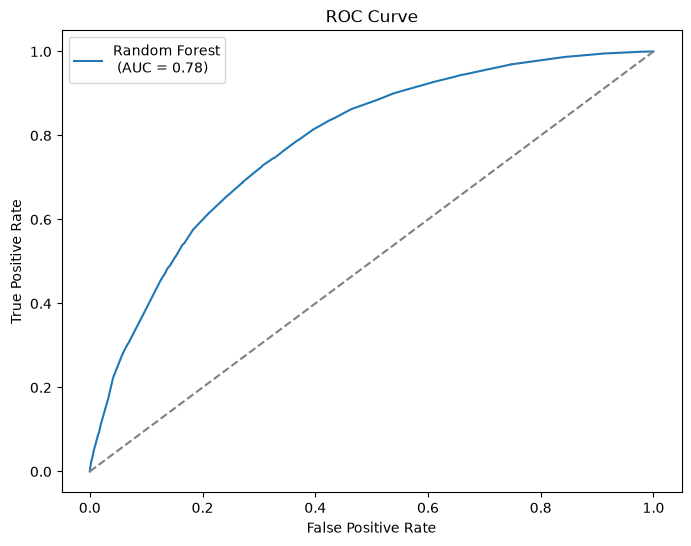

Confusion Matrix:
[[24389 12520]
 [ 1612  5067]]
Recall: 0.7586
Specificity: 0.6608
Precision: 0.2881
F1 Score: 0.4176
Accuracy: 0.6758


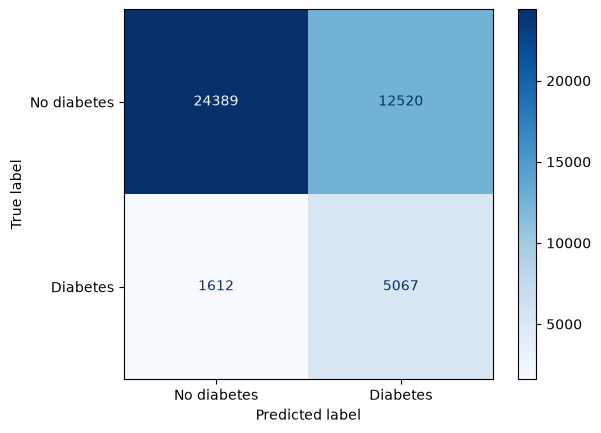

In [ ]:
cv_results = (
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")
    [["rank_test_score", "mean_test_score", "std_test_score", "params"]]
)
print("\nTop 5 CV candidates:")
print(cv_results.head())

best_params = search.best_params_.copy()

final_xgb = RandomForestClassifier(
    random_state         = 42,

    max_depth            = best_params.get("estimator__max_depth",         5),
    n_estimators         = best_params.get("estimator__n_estimators",     500),
    max_features         = best_params.get("estimator__max_features",     "sqrt"),
    min_samples_split    = best_params.get("estimator__min_samples_split", 2),
    min_samples_leaf     = best_params.get("estimator__min_samples_leaf", 1),
    bootstrap            = best_params.get("estimator__bootstrap",         True),
)

bb = BalancedBaggingClassifier(
    estimator        = final_xgb,
    n_estimators     = 50,           # full BBC bags for final model
    sampling_strategy= "auto",
    replacement      = False,
    random_state     = 42,
)

bb.fit(
	X_train,
	y_train
)

eval_set = [(X_train, y_train), (X_test, y_test)]


probs = bb.predict_proba(X_test)[:, 1]
preds = bb.predict(X_test)


print("Log loss:", log_loss(y_test, probs))


print(
    "Diabetes PR-AUC:",
    average_precision_score(y_test, probs)
)

fpr, tpr, thresholds = roc_curve(y_test, probs)

auc_score = roc_auc_score(y_test, probs)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Random Forest\n (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

confusion = confusion_matrix(y_test, preds)
tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()


recall = recall_score(y_test, preds)
specificity = tn/(tn + fp)
precision = tp/(fp + tp)
f1 = f1_score(y_test, preds)
accuracy = (tp + tn) / (tp + tn + fp + fn)
print('Confusion Matrix:')
print(confusion)
print(f"Recall: {recall:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Precision: {precision:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Accuracy: {accuracy:.4f}")
disp = ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=['No diabetes', 'Diabetes'])
disp.plot(cmap=plt.cm.Blues)

plt.show()